In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Data/producao-gas-natural-1000m3.csv", sep=';', decimal=';')

pd.options.display.float_format = '{:,.2f}'.format

df.head()

c:\Users\Pichau\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\Pichau\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


,ANO,MÊS,GRANDE REGIÃO,UNIDADE DA FEDERAÇÃO,PRODUTO,LOCALIZAÇÃO,PRODUÇÃO
0,1997,JAN,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,50891
1,1997,FEV,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,48632
2,1997,MAR,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,50528
3,1997,ABR,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,50588
4,1997,MAI,REGIÃO NORTE,AMAZONAS,GÁS NATURAL,TERRA,44179


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7709 entries, 0 to 7708
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   ANO                   7709 non-null   int64
 1   MÊS                   7709 non-null   str  
 2   GRANDE REGIÃO         7709 non-null   str  
 3   UNIDADE DA FEDERAÇÃO  7709 non-null   str  
 4   PRODUTO               7709 non-null   str  
 5   LOCALIZAÇÃO           7709 non-null   str  
 6   PRODUÇÃO              7709 non-null   str  
dtypes: int64(1), str(6)
memory usage: 796.9 KB


In [3]:
df['PRODUÇÃO'] = (
    df['PRODUÇÃO']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [4]:
producao_gn_ano = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('ANO')['PRODUÇÃO']
    .sum()
    .reset_index()
)

producao_gn_ano

,ANO,PRODUÇÃO
0,1997,"9,824,722.00"
1,1998,"10,787,604.00"
2,1999,"11,855,021.03"
3,2000,"13,282,877.05"
4,2001,"13,998,797.79"
5,2002,"15,525,153.14"
6,2003,"15,792,063.90"
7,2004,"16,971,155.99"
8,2005,"17,699,201.00"
9,2006,"17,706,161.48"


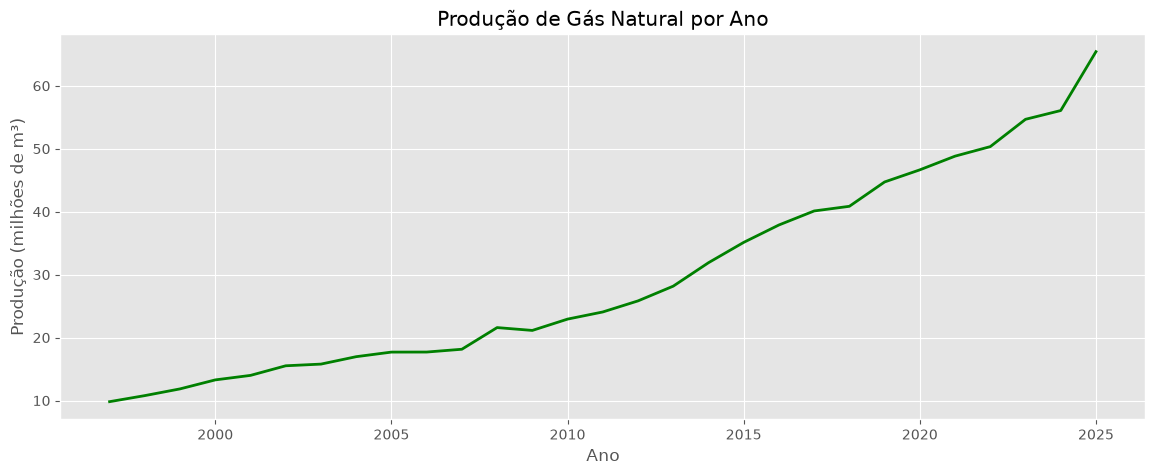

In [5]:
plt.figure(figsize=(14, 5))

plt.style.use('ggplot')

plt.plot(
    producao_gn_ano['ANO'],
    producao_gn_ano['PRODUÇÃO'] / 1e6,
    linewidth=2,
    color='green'
)

plt.title('Produção de Gás Natural por Ano')
plt.ylabel('Produção (milhões de m³)')
plt.xlabel('Ano');

In [6]:
producao_gn_local = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('LOCALIZAÇÃO')['PRODUÇÃO']
    .sum()
    .reset_index()
)

producao_gn_local

,LOCALIZAÇÃO,PRODUÇÃO
0,MAR,"658,392,401.69"
1,TERRA,"199,545,621.46"


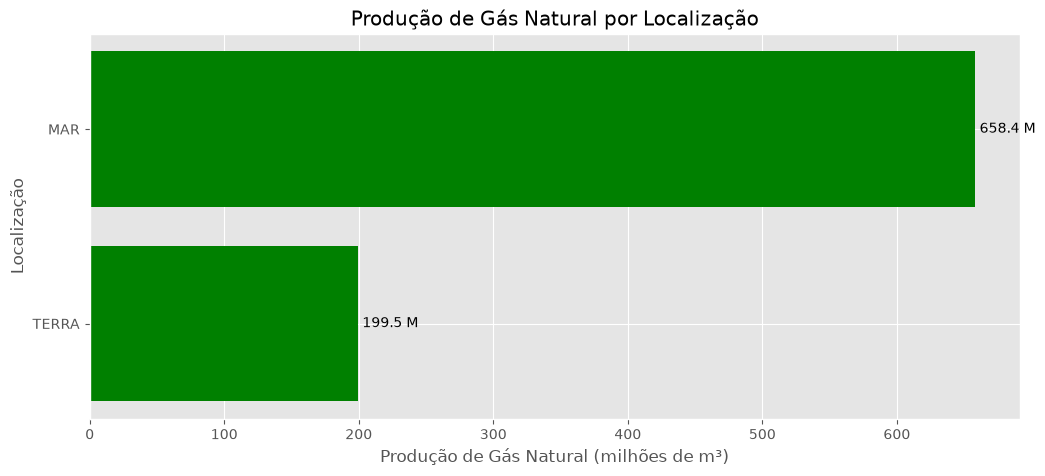

In [7]:
plt.figure(figsize=(12, 5))

plt.style.use('ggplot')

barras = plt.barh(
    producao_gn_local['LOCALIZAÇÃO'],
    producao_gn_local['PRODUÇÃO'] / 1e6,
    color='green'
)

plt.xlabel('Produção de Gás Natural (milhões de m³)')
plt.ylabel('Localização')
plt.title('Produção de Gás Natural por Localização')

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt='%.1f M', padding=3);

In [8]:
producao_gn_regiao = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('GRANDE REGIÃO')['PRODUÇÃO']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

producao_gn_regiao

,GRANDE REGIÃO,PRODUÇÃO
0,REGIÃO SUDESTE,"598,570,095.24"
1,REGIÃO NORDESTE,"147,518,302.93"
2,REGIÃO NORTE,"111,004,460.76"
3,REGIÃO SUL,"845,164.22"


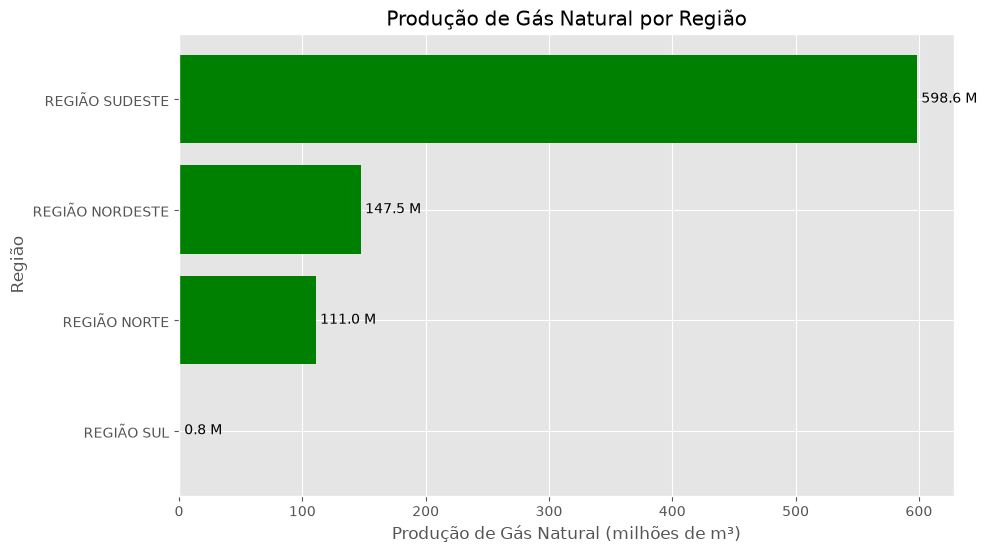

In [9]:
plt.figure(figsize=(10, 6))

plt.style.use('ggplot')

barras = plt.barh(
    producao_gn_regiao['GRANDE REGIÃO'],
    producao_gn_regiao['PRODUÇÃO'] / 1e6,
    color='green'
)

plt.title('Produção de Gás Natural por Região')
plt.xlabel('Produção de Gás Natural (milhões de m³)')
plt.ylabel('Região')

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt='%.1f M', padding=3);

In [10]:
producao_gn_uf = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('UNIDADE DA FEDERAÇÃO')['PRODUÇÃO']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

producao_gn_uf

,UNIDADE DA FEDERAÇÃO,PRODUÇÃO
0,RIO DE JANEIRO,"462,099,771.14"
1,AMAZONAS,"111,004,460.76"
2,SÃO PAULO,"78,639,805.85"
3,BAHIA,"66,770,049.08"
4,ESPÍRITO SANTO,"57,830,518.25"
5,RIO GRANDE DO NORTE,"21,585,921.64"
6,MARANHÃO,"19,710,714.60"
7,SERGIPE,"19,573,721.38"
8,ALAGOAS,"18,264,220.20"
9,CEARÁ,"1,613,676.03"


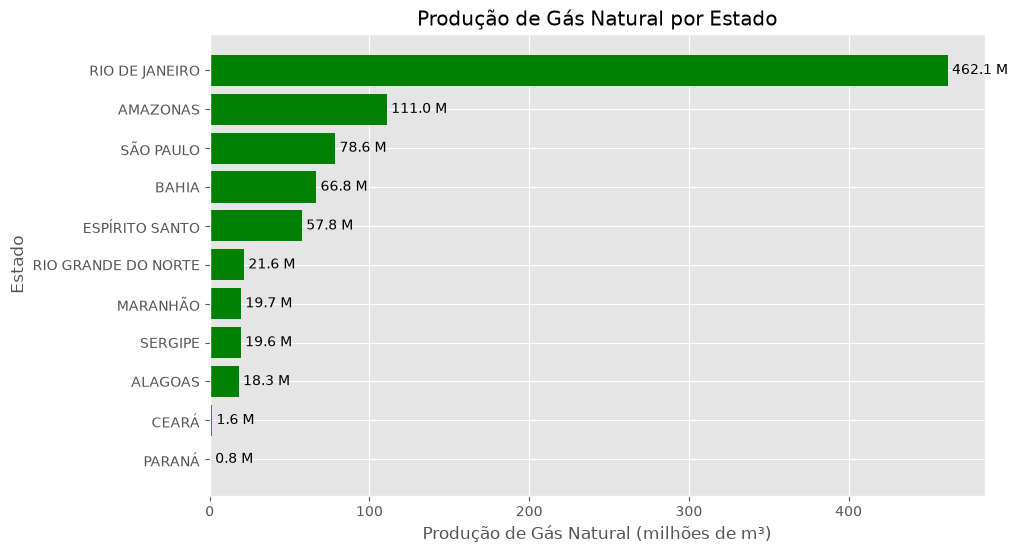

In [11]:
plt.figure(figsize=(10, 6))

plt.style.use('ggplot')

barras = plt.barh(
    producao_gn_uf['UNIDADE DA FEDERAÇÃO'],
    producao_gn_uf['PRODUÇÃO'] / 1e6,
    color='green'
)

plt.title('Produção de Gás Natural por Estado')
plt.xlabel('Produção de Gás Natural (milhões de m³)')
plt.ylabel('Estado')

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt='%.1f M', padding=3);

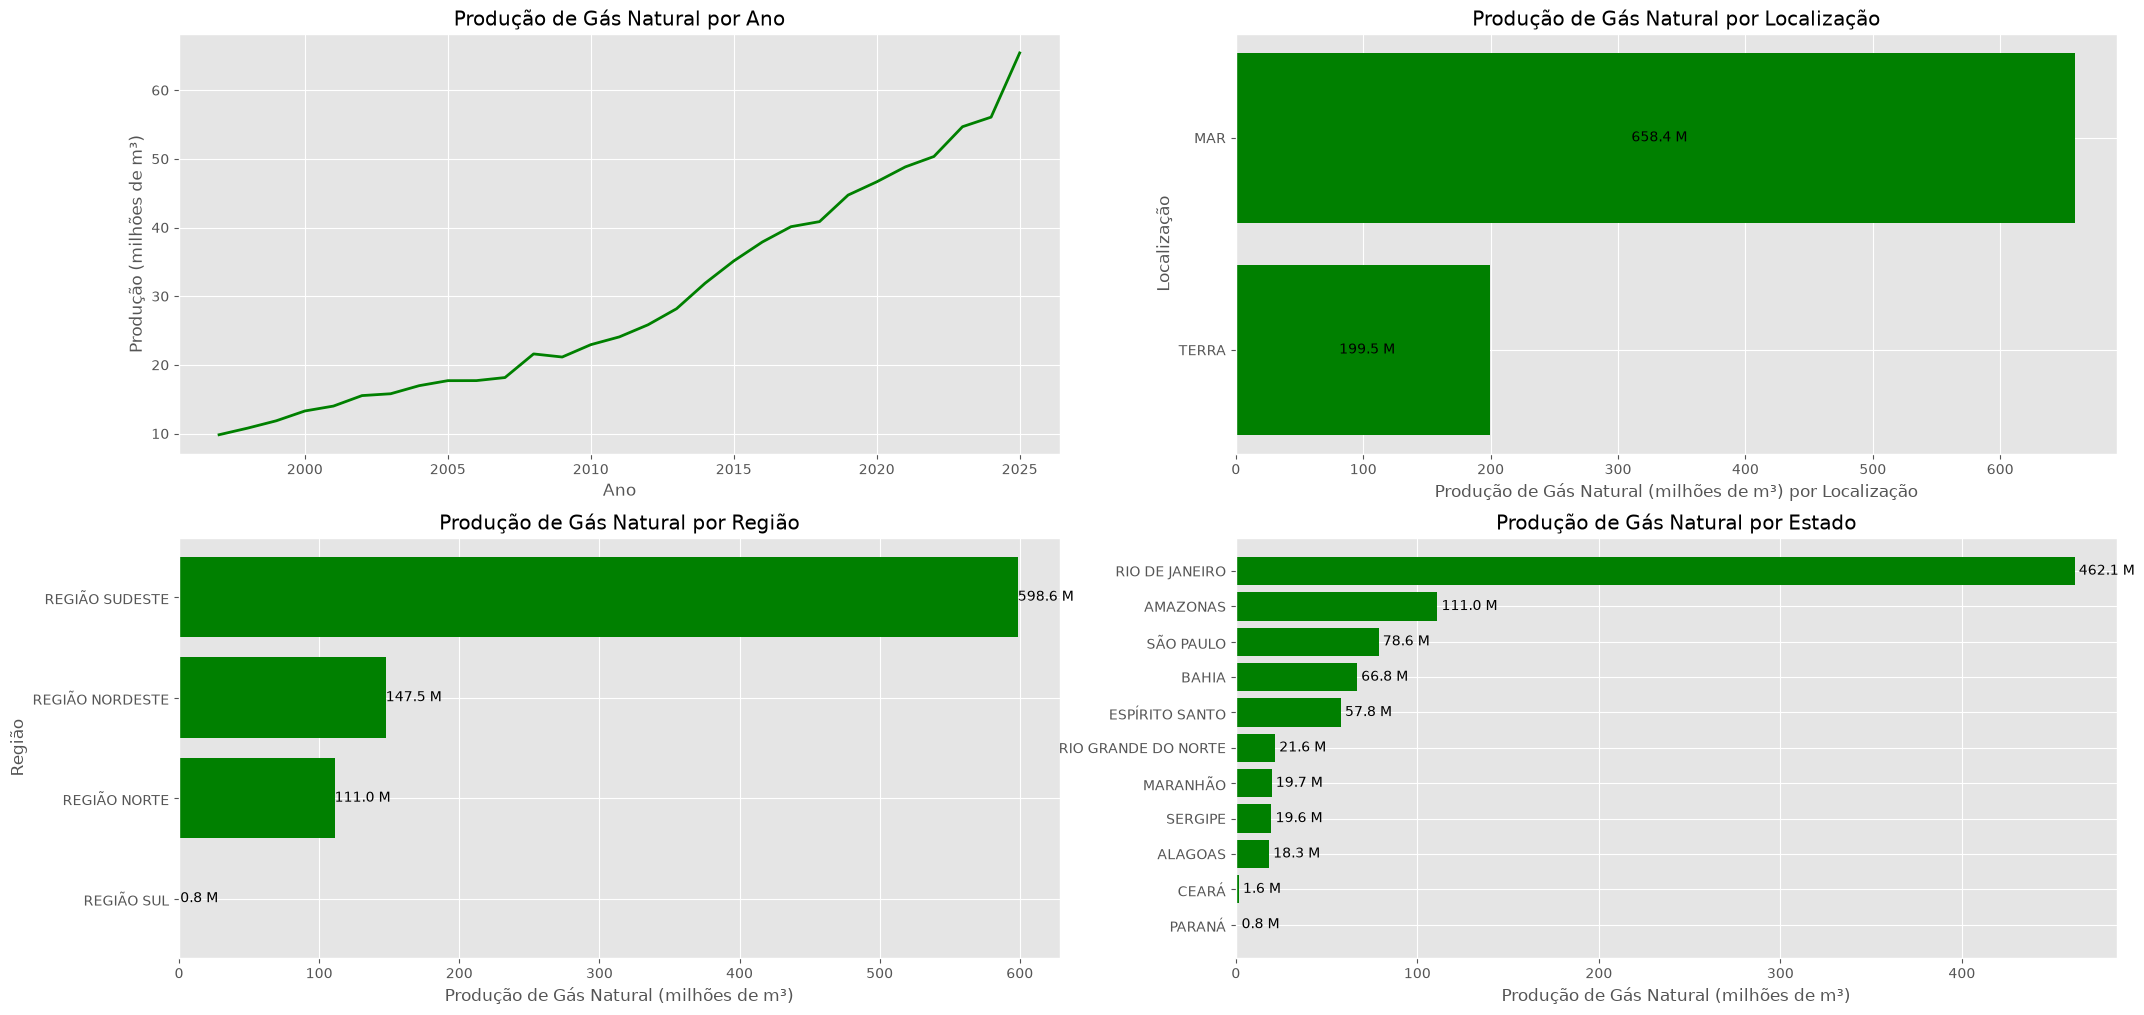

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(25, 12))

plt.style.use('ggplot')

ax[0, 0].plot(
    producao_gn_ano['ANO'],
    producao_gn_ano['PRODUÇÃO'] / 1e6,
    linewidth=2,
    color='green'
)

ax[0, 0].set_title('Produção de Gás Natural por Ano')
ax[0, 0].set_ylabel('Produção (milhões de m³)')
ax[0, 0].set_xlabel('Ano')

barras = ax[0, 1].barh(
    producao_gn_local['LOCALIZAÇÃO'],
    producao_gn_local['PRODUÇÃO'] / 1e6,
    color='green'
)

ax[0, 1].set_title('Produção de Gás Natural por Localização')
ax[0, 1].set_ylabel('Localização')
ax[0, 1].set_xlabel('Produção de Gás Natural (milhões de m³) por Localização')
ax[0, 1].bar_label(barras, fmt='%.1f M', padding=3, label_type='center')
ax[0, 1].invert_yaxis()

barras = ax[1, 0].barh(
    producao_gn_regiao['GRANDE REGIÃO'],
    producao_gn_regiao['PRODUÇÃO'] / 1e6,
    color='green'
)

ax[1, 0].set_title('Produção de Gás Natural por Região')
ax[1, 0].set_xlabel('Produção de Gás Natural (milhões de m³)')
ax[1, 0].set_ylabel('Região')
ax[1, 0].invert_yaxis()
ax[1, 0].bar_label(barras, fmt='%.1f M', padding=0)

barras = ax[1, 1].barh(
    producao_gn_uf['UNIDADE DA FEDERAÇÃO'],
    producao_gn_uf['PRODUÇÃO'] / 1e6,
    color='green'
)

ax[1, 1].set_title('Produção de Gás Natural por Estado')
ax[1, 1].set_xlabel('Produção de Gás Natural (milhões de m³)')
ax[1, 1].invert_yaxis()
ax[1, 1].bar_label(barras, fmt='%.1f M', padding=3);

In [13]:
df.to_csv(
    'producao_gn.csv',
    sep=';',
    decimal=',',
    index=False
)